# Flexibilizações de preço e metas semanais

**Pergunta.** Quanto é necessário flexibilizar cada regra operacional para tornar possível o
planejamento de dez dias úteis, e como a margem prevista responde a flexibilizações adicionais?

O estudo recebe artefatos persistidos: entradas do planejamento e curva preditiva. Mantém o preço
anterior observado, o custo do último dia de treino, o imposto e o calendário desses artefatos.
Cada ponto das análises corresponde a um novo problema de maximização da margem com as regras
explicitadas. A execução é independente do estado de outros notebooks e não lê o holdout.

A exposição apresenta primeiro o modelo, as entradas e o significado das mudanças. Depois calcula
os mínimos de viabilidade, as curvas de margem e as combinações. As saídas são planos condicionais
às regras alteradas; o estudo não escolhe automaticamente qual flexibilização o negócio deve aceitar.

## 1. Modelo, regras e premissas

O objetivo é a soma, nos dez dias, da receita prevista líquida de imposto menos o custo dos quilos
previstos. O preço é a decisão; o volume fica ligado ao preço pela curva publicada, incluindo
calendário e smearing. A igualdade com a curva é mantida em todas as análises.

$$\max \sum_t [(1-\tau)p_t-c]q_t,\qquad
q_t=SF\exp(\beta_0+\gamma_{c(t)})p_t^\beta.$$

As regras de referência são os limites semanais, o suporte de preço por contexto, a mudança entre
decisões consecutivas e a ligação entre o preço anterior e a primeira decisão. Sexta e segunda são
consecutivas para a regra de preço. O limite da primeira mudança é independente do limite interno.

| Parâmetro alterado | Significado | Regras preservadas na análise isolada |
|---|---|---|
| Variação interna | Aumentar o máximo de mudança entre os dias do horizonte | Primeira mudança e faixa semanal |
| Transição inicial | Aumentar a primeira mudança permitida, conservando o preço anterior real | Variação interna e faixa semanal |
| Tolerância inferior | Reduzir o piso semanal, mantendo o teto | Ambas as regras de preço |
| Tolerância superior | Aumentar o teto semanal, mantendo o piso | Ambas as regras de preço |
| Meta nominal | Deslocar piso e teto pela mesma meta | Tolerâncias e ambas as regras de preço |

Aumentar uma folga amplia o conjunto de planos admissíveis. A margem ótima não pode diminuir
nessa operação; diferenças dentro do gap numérico não indicam uma perda econômica demonstrada.
Alterar a meta nominal desloca a faixa e **não** gera conjuntos necessariamente aninhados.

**Premissas.** Um produto, preços contínuos, curva fixa e observacional, previsão pontual e demanda
prevista integralmente atendida. Custo unitário e imposto permanecem constantes. Não há estoque,
capacidade, efeitos entre produtos ou transferência de demanda entre dias. O suporte observado
permanece obrigatório neste estudo. O volume previsto não é uma garantia de venda realizada.

In [1]:
from pathlib import Path
from itertools import product
import json
import sys

import matplotlib.pyplot as plt
from matplotlib.colors import Normalize
import numpy as np
import pandas as pd
from IPython.display import Markdown, display

ROOT = Path.cwd()
if not (ROOT / 'src').exists():
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))

from src.modeling.demand_curve import file_sha256
from src.optimization.planning_inputs import load_planning_inputs
from src.optimization.relaxation_study import (
    Relaxation, RelaxationStudy, pareto_feasible, summarize,
)

INPUT_PATH = ROOT / 'models/otimizacao/entradas_planejamento.json'
TABLES = ROOT / 'reports/tables/relaxacoes'
FIGURES = ROOT / 'reports/figures/relaxacoes'
RESULT_PATH = ROOT / 'data/processed/minerva_simulacao_relaxacoes.json'
PLAN_PATH = ROOT / 'data/processed/minerva_planos_relaxacoes.csv'
for folder in [TABLES, FIGURES, RESULT_PATH.parent]:
    folder.mkdir(parents=True, exist_ok=True)

problem, planning_inputs = load_planning_inputs(INPUT_PATH, root=ROOT)
MODEL_PATH = ROOT / planning_inputs['model_file']
input_hash = file_sha256(INPUT_PATH)
model_hash = file_sha256(MODEL_PATH)
study = RelaxationStudy(problem, time_limit=30, mip_gap=1e-6)
BASE = study.evaluate()
nominal_target = next(iter(problem.targets.values()))
assert len(set(problem.targets.values())) == 1, 'O painel usa uma meta nominal comum às semanas.'
STATUS = {
    'optimal': 'Ótimo certificado', 'infeasible': 'Inviável provado',
    'feasible_time_limit': 'Plano verificado; limite de tempo',
    'feasible_suboptimal': 'Plano verificado; sem certificado',
    'feasible_unproven': 'Plano verificado; sem certificado',
    'no_solution': 'Sem solução encontrada', 'error': 'Erro de execução',
    'validation_failed': 'Falha de verificação',
}
LABELS = {
    'daily_variation': 'Variação interna', 'initial_transition': 'Transição inicial',
    'tolerance_lower': 'Tolerância inferior', 'tolerance_upper': 'Tolerância superior',
}
plt.rcParams.update({'figure.dpi': 110, 'font.size': 10, 'axes.spines.top': False,
                     'axes.spines.right': False})
pd.set_option('display.max_columns', 20)

def numero(valor, casas=2):
    return f'{valor:,.{casas}f}'.replace(',', '_').replace('.', ',').replace('_', '.')

def publicar(texto):
    display(Markdown(texto))

def avaliar_regra(regra, valores, **conditions):
    return [dict(regra=regra, valor=float(value), **summarize(
        study.evaluate(study.relaxation_at(regra, float(value)), **conditions)))
        for value in sorted(set(valores))]

inputs = pd.DataFrame([
    ('Entradas recebidas', str(INPUT_PATH.relative_to(ROOT))),
    ('Curva recebida', planning_inputs['model_file']),
    ('Corte das entradas', planning_inputs['decision_cutoff']),
    ('Preço anterior observado (R$/kg)', problem.initial_price),
    ('Custo do último dia de treino (R$/kg)', problem.costs[0]),
    ('Imposto sobre receita', problem.tax_rate),
    ('Meta nominal por semana (kg)', nominal_target),
    ('Tolerância inferior', problem.tol_lower),
    ('Tolerância superior', problem.tol_upper),
    ('Variação interna (R$/kg)', problem.daily_variation),
    ('Primeira mudança (R$/kg)', problem.init_var),
    ('Smearing', problem.artifact['smearing_factor']),
], columns=['Entrada', 'Valor'])
display(inputs)
display(pd.DataFrame.from_dict(BASE['diagnostics']['weeks'], orient='index')[[
    'lower_kg', 'upper_kg', 'minimum_reachable_kg', 'maximum_reachable_kg', 'shortage_kg'
]].round(3))
publicar(f"**Interpretação das entradas.** O caso de referência é **{STATUS[BASE['status']].lower()}**. "
         f"O preço anterior é R$ {numero(problem.initial_price)}/kg, o custo fixo é "
         f"R$ {numero(problem.costs[0], 6)}/kg e o smearing recebido é "
         f"{numero(problem.artifact['smearing_factor'], 7)}. A curva e as fontes são conferidas "
         "contra os hashes do artefato de entradas antes de resolver qualquer flexibilização.")

2026-11-08 17:14:13.444 | INFO     | src.config:<module>:11 - PROJ_ROOT path is: /Users/ngodeny/Documents/mestrado/202602-resolucao_problemas


,Entrada,Valor
0,Entradas recebidas,models/otimizacao/entradas_planejamento.json
1,Curva recebida,models/preditivo_diario/curva_demanda.json
2,Corte das entradas,2025-10-31
3,Preço anterior observado (R$/kg),1318.919594
4,Custo do último dia de treino (R$/kg),1010.446838
5,Imposto sobre receita,0.07
6,Meta nominal por semana (kg),165.0
7,Tolerância inferior,0.3
8,Tolerância superior,0.3
9,Variação interna (R$/kg),2.0


,lower_kg,upper_kg,minimum_reachable_kg,maximum_reachable_kg,shortage_kg
semana_1,115.5,214.5,69.694,76.987,38.513
semana_2,115.5,214.5,63.503,84.616,30.884


**Interpretação das entradas.** O caso de referência é **inviável provado**. O preço anterior é R$ 1.318,92/kg, o custo fixo é R$ 1.010,446838/kg e o smearing recebido é 1,0912057. A curva e as fontes são conferidas contra os hashes do artefato de entradas antes de resolver qualquer flexibilização.

## 2. Como são encontrados os mínimos de viabilidade

**Pergunta.** Qual é a menor ampliação de uma regra que permite um plano válido, mantendo as demais?

**Método.** Para limites de mudança e tolerâncias, a busca por bisseção conserva um valor inviável
provado e outro com plano verificado. Um envelope de volume que não alcança a faixa semanal
certifica inviabilidade; a interseção com a faixa, por si só, não comprova a existência de um plano.
A factibilidade é confirmada pelo solver e pela recomposição das restrições.

A precisão é R$ 0,001/kg para mudanças de preço e 0,000001 para frações de tolerância.
O mínimo é apresentado pelo lado factível do intervalo. A margem desse ponto é maximizada com
Gurobi, usando o mesmo objetivo e gap da análise de referência. Terminar sem encontrar solução
não é convertido em inviabilidade.

Para o teto semanal, testa-se se ampliá-lo pode recuperar o caso. Uma alteração que não resolve a
causa da inviabilidade é reportada como sem recuperação na faixa examinada, sem atribuir margem.
Não se busca mínimo por bisseção para a meta nominal, pois essa mudança desloca os dois limites.

In [2]:
limits = {
    'daily_variation': (35.0, 1e-3),
    'initial_transition': (120.0, 1e-3),
    'tolerance_lower': (.95, 1e-6),
    'tolerance_upper': (.95, 1e-6),
}
thresholds = [study.minimum(rule, upper=upper, precision=precision)
              for rule, (upper, precision) in limits.items()]
threshold_table = pd.DataFrame(thresholds)
threshold_table['regra'] = threshold_table['rule'].map(LABELS)
threshold_table['piso_resultante_kg'] = np.where(
    threshold_table['rule'] == 'tolerance_lower',
    nominal_target * (1 - threshold_table['minimum']), np.nan)
threshold_table.to_csv(TABLES / 'limiares_viabilidade.csv', index=False)
display(threshold_table[['regra', 'status', 'infeasible_value', 'feasible_value',
                         'precision', 'piso_resultante_kg', 'margem_prevista_rs']].round(6))
minimum = {row['rule']: row['minimum'] for row in thresholds}
assert all(minimum[rule] is not None for rule in ['daily_variation', 'initial_transition', 'tolerance_lower'])
publicar(
    f"**Interpretação dos mínimos.** Preservando a primeira mudança em "
    f"R$ {numero(problem.init_var)}/kg, a variação interna precisa chegar a aproximadamente "
    f"**R$ {numero(minimum['daily_variation'], 3)}/kg**. Mantendo a variação interna em "
    f"R$ {numero(problem.daily_variation)}/kg, a primeira mudança precisa admitir aproximadamente "
    f"**R$ {numero(minimum['initial_transition'], 3)}/kg**. São alternativas distintas, ambas "
    "calculadas a partir do preço anterior observado.\n\n"
    f"Alterar somente o piso exige tolerância inferior de aproximadamente "
    f"**{numero(100 * minimum['tolerance_lower'], 4)}%**, equivalente a um piso comum de "
    f"**{numero(nominal_target * (1 - minimum['tolerance_lower']))} kg**. O teto permanece "
    f"{numero(nominal_target * (1 + problem.tol_upper), 1)} kg. Aumentar somente o teto não "
    "recupera o caso: o piso exigido supera o máximo de volume alcançável com as regras de preço."
)

,regra,status,infeasible_value,feasible_value,precision,piso_resultante_kg,margem_prevista_rs
0,Variação interna,bracketed,24.670883,24.671387,0.001000,NaN,43847.123906
1,Transição inicial,bracketed,44.392746,44.393646,0.001000,NaN,40520.378388
2,Tolerância inferior,bracketed,0.533413,0.533413,0.000001,76.986795,33336.935447
3,Tolerância superior,no_recovery_in_range,0.950000,NaN,0.000001,NaN,NaN


**Interpretação dos mínimos.** Preservando a primeira mudança em R$ 2,00/kg, a variação interna precisa chegar a aproximadamente **R$ 24,671/kg**. Mantendo a variação interna em R$ 2,00/kg, a primeira mudança precisa admitir aproximadamente **R$ 44,394/kg**. São alternativas distintas, ambas calculadas a partir do preço anterior observado.

Alterar somente o piso exige tolerância inferior de aproximadamente **53,3413%**, equivalente a um piso comum de **76,99 kg**. O teto permanece 214,5 kg. Aumentar somente o teto não recupera o caso: o piso exigido supera o máximo de volume alcançável com as regras de preço.

## 3. Curvas graduais de preço e piso semanal

**Pergunta.** Depois de recuperar a viabilidade, quanto de margem prevista cada folga adicional permite?

**Método.** Cada curva altera somente uma regra. O eixo de piso mostra kg admitidos; reduzir esse
piso aumenta a tolerância inferior. Pontos inviáveis permanecem nas tabelas e aparecem por marcas
vermelhas na base dos painéis. A linha tracejada indica o mínimo calculado, e as margens usam a
mesma escala vertical. Os planos permanecem dentro do suporte observado.

Os valores das grades são escolhas de resolução da análise. Os mínimos vêm da busca própria, e
não da primeira posição factível da grade. Margens são previstas e condicionais à curva recebida.

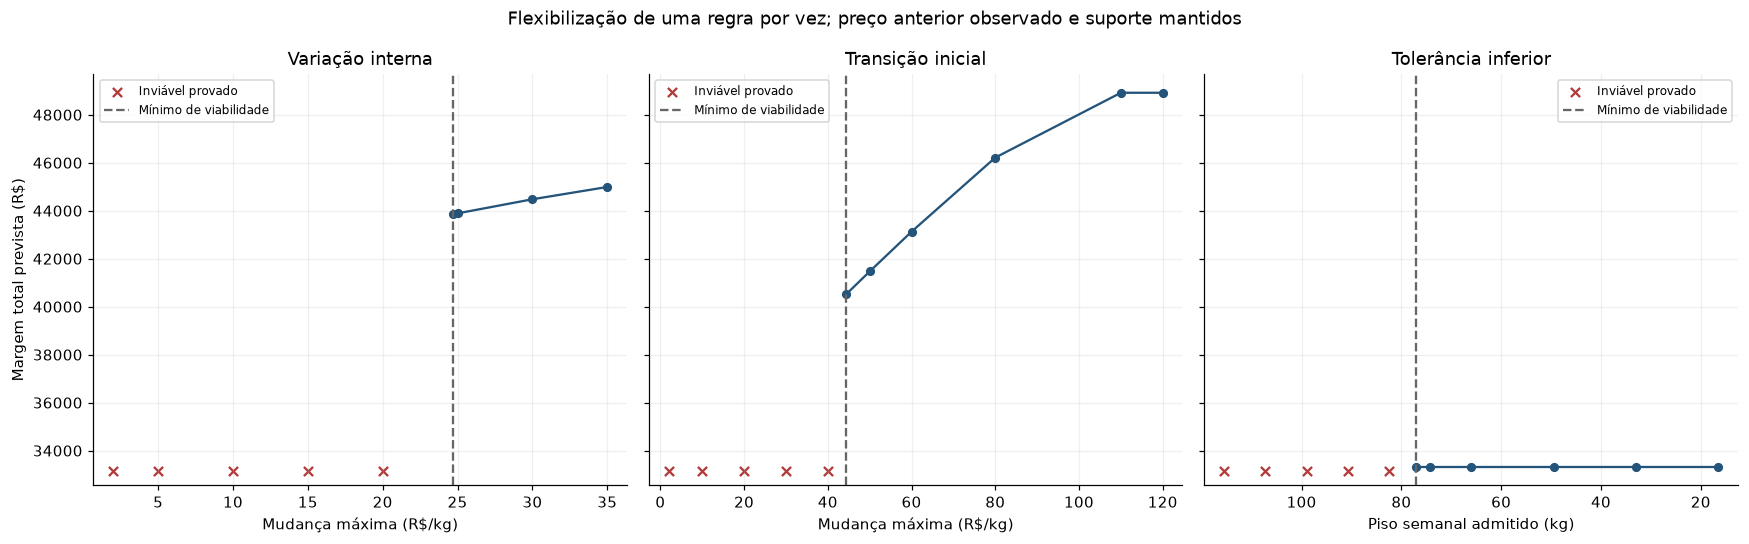

**Variação interna.** Nas posições factíveis da grade, a margem prevista fica entre R$ 43.847,12 e R$ 44.989,98.

**Transição inicial.** Nas posições factíveis da grade, a margem prevista fica entre R$ 40.520,38 e R$ 48.917,58.

**Tolerância inferior.** Nas posições factíveis da grade, a margem prevista fica entre R$ 33.336,94 e R$ 33.336,94.

Reduzir apenas o piso permite aceitar volumes menores, preservando a trajetória de preços alcançável. Isso recupera a viabilidade sem criar a mesma liberdade comercial de ampliar as mudanças de preço. Um patamar de margem indica que ampliar aquela folga já não altera a melhor decisão sob as outras regras mantidas.

In [3]:
grids = {
    'daily_variation': [2, 5, 10, 15, 20, 25, 30, 35, minimum['daily_variation']],
    'initial_transition': [2, 10, 20, 30, 40, 50, 60, 80, 110, 120, minimum['initial_transition']],
    'tolerance_lower': [.30, .35, .40, .45, .50, .55, .60, .70, .80, .90, minimum['tolerance_lower']],
}
curve_rows = []
for rule, values in grids.items():
    curve_rows.extend(avaliar_regra(rule, values))
curves = pd.DataFrame(curve_rows)
curves.to_csv(TABLES / 'curvas.csv', index=False)
fig, axes = plt.subplots(1, 3, figsize=(16, 5), sharey=True)
for ax, rule in zip(axes, grids):
    panel = curves.loc[curves['regra'] == rule].sort_values('valor')
    x = panel['valor'].to_numpy()
    boundary = minimum[rule]
    if rule == 'tolerance_lower':
        x = nominal_target * (1 - x)
        boundary = nominal_target * (1 - boundary)
    padding = max(float(np.ptp(x)) * .04, .1)
    ax.set_xlim(x.min() - padding, x.max() + padding)
    if rule == 'tolerance_lower':
        ax.invert_xaxis()
    ax.plot(x, panel['margem_prevista_rs'], 'o-', color='#24547a', ms=5)
    failed = panel['status'].eq('infeasible').to_numpy()
    ax.scatter(x[failed], np.full(failed.sum(), .035), transform=ax.get_xaxis_transform(),
               color='#b23b3b', marker='x', label='Inviável provado')
    ax.axvline(boundary, color='0.4', ls='--', label='Mínimo de viabilidade')
    ax.set_title(LABELS[rule])
    ax.set_xlabel('Piso semanal admitido (kg)' if rule == 'tolerance_lower' else 'Mudança máxima (R$/kg)')
    ax.grid(alpha=.2)
    ax.legend(fontsize=8)
axes[0].set_ylabel('Margem total prevista (R$)')
fig.suptitle('Flexibilização de uma regra por vez; preço anterior observado e suporte mantidos')
fig.tight_layout()
fig.savefig(FIGURES / 'curvas.png', dpi=160, bbox_inches='tight')
plt.show()
for rule in grids:
    valid = curves.loc[(curves['regra'] == rule) & curves['plano_verificado']]
    publicar(f"**{LABELS[rule]}.** Nas posições factíveis da grade, a margem prevista fica entre "
             f"R$ {numero(valid['margem_prevista_rs'].min())} e "
             f"R$ {numero(valid['margem_prevista_rs'].max())}.")
publicar('Reduzir apenas o piso permite aceitar volumes menores, preservando a trajetória de preços '
         'alcançável. Isso recupera a viabilidade sem criar a mesma liberdade comercial de ampliar '
         'as mudanças de preço. Um patamar de margem indica que ampliar aquela folga já não altera '
         'a melhor decisão sob as outras regras mantidas.')

## 4. Efeito do teto semanal após recuperar a viabilidade

**Pergunta.** O teto deixa de importar porque sua flexibilização isolada não recupera o caso?

**Método.** A tolerância superior é variada em duas condições explícitas: regras de preço de
referência; e primeira ligação removida, mantendo a variação interna. A segunda condição permite
examinar o efeito do teto em um problema factível. A tolerância inferior e a meta nominal não mudam.

Essa comparação separa recuperar a viabilidade de ampliar a margem. As duas condições não devem
ser apresentadas como se fossem o mesmo conjunto de regras.

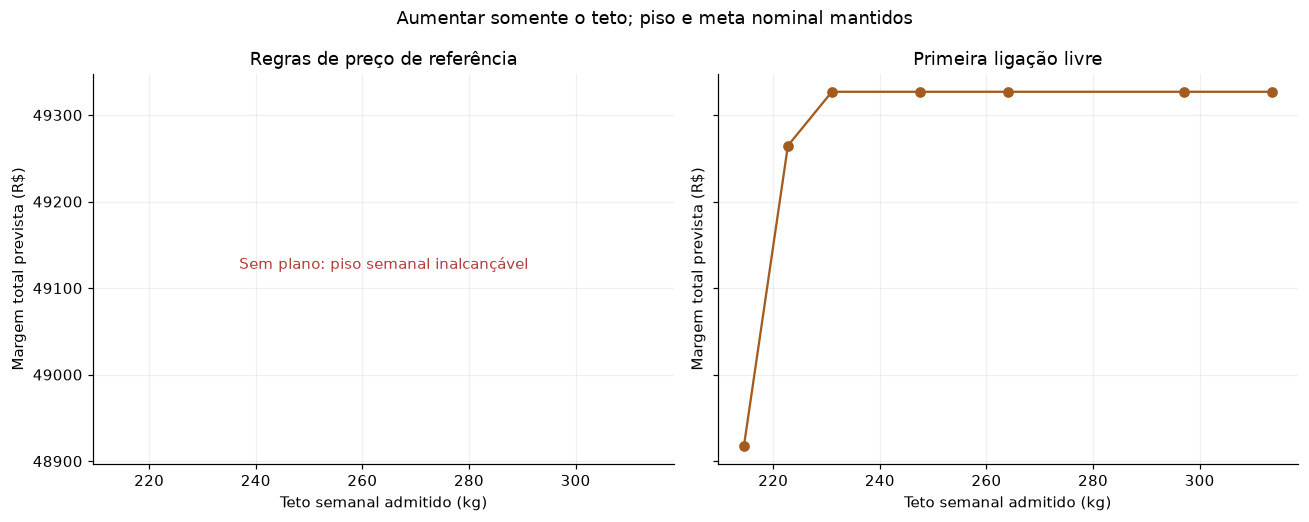

**Interpretação.** A ampliação do teto não resolve o déficit do caso de referência. Com a primeira ligação livre, o teto pode limitar o volume que maximiza a margem. Nessa condição, a grade apresenta margens entre R$ 48.917,58 e R$ 49.326,90. Essas diferenças são simuladas sob uma exceção operacional declarada.

In [4]:
upper_rows = []
for free_initial in [False, True]:
    condition = 'Primeira ligação livre' if free_initial else 'Regras de preço de referência'
    for row in avaliar_regra('tolerance_upper', [.30, .35, .40, .50, .60, .80, .90],
                             enforce_initial=not free_initial):
        upper_rows.append(dict(condicao=condition, **row))
upper_curves = pd.DataFrame(upper_rows)
upper_curves.to_csv(TABLES / 'curva_teto.csv', index=False)
fig, axes = plt.subplots(1, 2, figsize=(12, 4.8), sharex=True, sharey=True)
for ax, (condition, panel) in zip(axes, upper_curves.groupby('condicao', sort=False)):
    x = nominal_target * (1 + panel['valor'])
    ax.plot(x, panel['margem_prevista_rs'], 'o-', color='#a35b20')
    if not panel['plano_verificado'].any():
        ax.text(.5, .5, 'Sem plano: piso semanal inalcançável', transform=ax.transAxes,
                ha='center', wrap=True, color='#b23b3b')
    ax.set(title=condition, xlabel='Teto semanal admitido (kg)', ylabel='Margem total prevista (R$)')
    ax.grid(alpha=.2)
fig.suptitle('Aumentar somente o teto; piso e meta nominal mantidos')
fig.tight_layout()
fig.savefig(FIGURES / 'curva_teto.png', dpi=160, bbox_inches='tight')
plt.show()
conditional = upper_curves.loc[upper_curves['plano_verificado']]
publicar(f"**Interpretação.** A ampliação do teto não resolve o déficit do caso de referência. "
         "Com a primeira ligação livre, o teto pode limitar o volume que maximiza a margem. "
         f"Nessa condição, a grade apresenta margens entre R$ "
         f"{numero(conditional['margem_prevista_rs'].min())} e R$ "
         f"{numero(conditional['margem_prevista_rs'].max())}. Essas diferenças são simuladas "
         "sob uma exceção operacional declarada.")

## 5. Sensibilidade da meta nominal

**Pergunta.** O que muda quando a própria meta semanal é reduzida ou aumentada?

**Método.** A meta comum às duas semanas é variada, conservando as tolerâncias, o preço anterior,
as duas regras de mudança e o suporte. Reduzir a meta abaixa simultaneamente o piso e o teto.
Por isso, uma meta muito baixa também pode ser inviável: a trajetória de preço pode não permitir
reduzir o volume até o teto. Não se interpreta essa curva como uma flexibilização monotônica.

,meta_kg,status,margem_prevista_rs,semana_1_piso_kg,semana_1_teto_kg
0,40.0,infeasible,NaN,28.0,52.0
1,50.0,infeasible,NaN,35.0,65.0
2,60.0,optimal,32627.890,42.0,78.0
3,70.0,optimal,33336.935,49.0,91.0
4,80.0,optimal,33336.935,56.0,104.0
5,90.0,optimal,33336.935,63.0,117.0
6,100.0,optimal,33336.935,70.0,130.0
7,110.0,infeasible,NaN,77.0,143.0
8,125.0,infeasible,NaN,87.5,162.5
9,140.0,infeasible,NaN,98.0,182.0


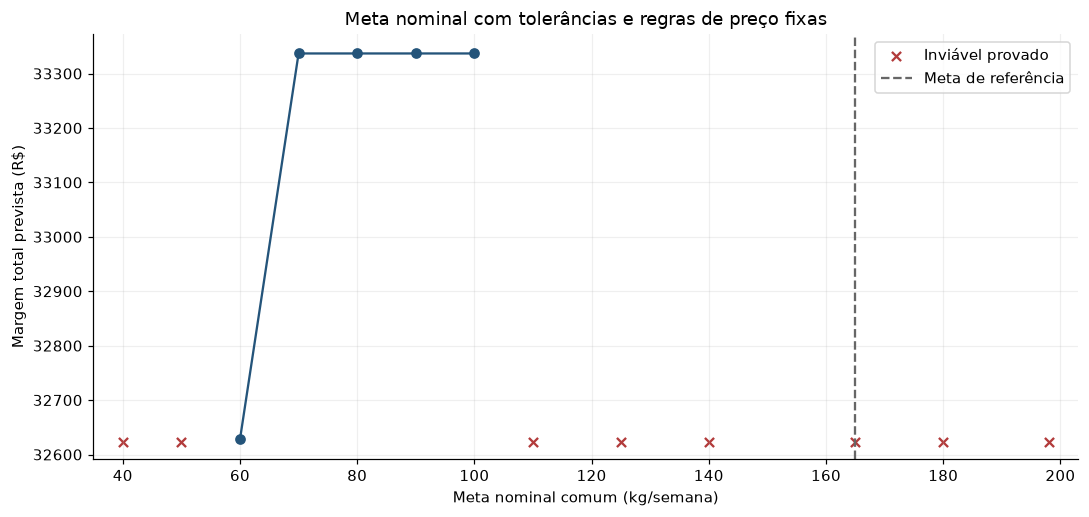

**Interpretação.** Na grade examinada, há planos válidos para metas de 60 a 100 kg. Esses são pontos amostrados, não os limites exatos de um intervalo contínuo. As margens devem ser lidas com a faixa de volume correspondente a cada meta.

In [5]:
target_rows = []
for target in [40, 50, 60, 70, 80, 90, 100, 110, 125, 140, 165, 180, 198]:
    row = summarize(study.evaluate(Relaxation(target_nominal_factor=target / nominal_target)))
    target_rows.append(dict(meta_kg=float(target), **row))
target_curve = pd.DataFrame(target_rows)
target_curve.to_csv(TABLES / 'sensibilidade_meta_nominal.csv', index=False)
display(target_curve[['meta_kg', 'status', 'margem_prevista_rs',
                      'semana_1_piso_kg', 'semana_1_teto_kg']].round(3))
fig, ax = plt.subplots(figsize=(10, 4.8))
ax.plot(target_curve['meta_kg'], target_curve['margem_prevista_rs'], 'o-', color='#24547a')
failed = target_curve['status'].eq('infeasible')
ax.scatter(target_curve.loc[failed, 'meta_kg'], np.full(failed.sum(), .04), marker='x',
           color='#b23b3b', transform=ax.get_xaxis_transform(), label='Inviável provado')
ax.set_xlim(target_curve['meta_kg'].min() - 5, target_curve['meta_kg'].max() + 5)
ax.axvline(nominal_target, color='0.4', ls='--', label='Meta de referência')
ax.set(title='Meta nominal com tolerâncias e regras de preço fixas',
       xlabel='Meta nominal comum (kg/semana)', ylabel='Margem total prevista (R$)')
ax.grid(alpha=.2)
ax.legend()
fig.tight_layout()
fig.savefig(FIGURES / 'meta_nominal.png', dpi=160, bbox_inches='tight')
plt.show()
valid_targets = target_curve.loc[target_curve['plano_verificado'], 'meta_kg']
publicar(f"**Interpretação.** Na grade examinada, há planos válidos para metas de "
         f"{numero(valid_targets.min(), 0)} a {numero(valid_targets.max(), 0)} kg. "
         "Esses são pontos amostrados, não os limites exatos de um intervalo contínuo. "
         "As margens devem ser lidas com a faixa de volume correspondente a cada meta.")

## 6. Combinações de flexibilizações e fronteiras na grade

**Pergunta.** Pequenas alterações simultâneas podem recuperar a viabilidade sem uma grande alteração isolada?

**Método.** Três grades cruzam transição inicial e variação interna; variação interna e redução do
piso; transição inicial e redução do piso. A terceira regra e o teto permanecem na referência.
Cada célula registra status, limites declarados, margem, volumes e folgas.

As cores representam margem de planos verificados. Células cinzas são inviáveis provadas. A
fronteira marca combinações factíveis para as quais nenhuma outra posição da mesma grade exige
alterações menores nas duas regras. Cada eixo permanece na sua unidade. A margem é reportada,
mas não entra em uma soma arbitrária com R$ de mudança ou kg de meta.

A fronteira é aproximada pela grade: ela não comprova o mínimo contínuo de cada combinação.

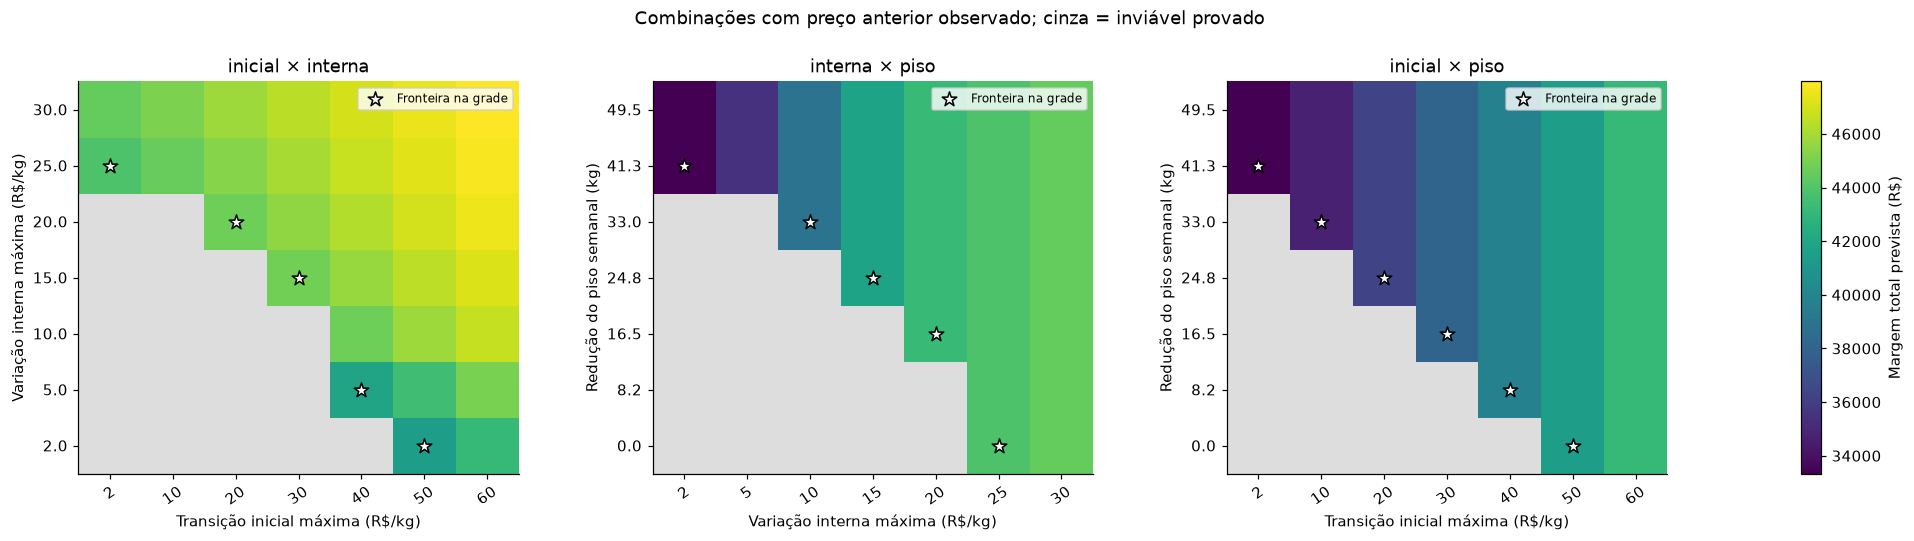

,par,x,y,margem_prevista_rs,case_id
0,inicial_interna,2.0,25.00,43889.902,c0062
1,inicial_interna,20.0,20.00,44705.077,c0115
2,inicial_interna,30.0,15.00,44865.390,c0120
3,inicial_interna,40.0,5.00,41845.012,c0124
4,inicial_interna,50.0,2.00,41468.431,c0068
5,interna_piso,2.0,41.25,33336.935,c0076
6,interna_piso,10.0,33.00,38922.710,c0151
7,interna_piso,15.0,24.75,41802.318,c0156
8,interna_piso,20.0,16.50,43202.784,c0161
9,interna_piso,25.0,0.00,43889.902,c0062


**Interpretação.** Foram avaliadas 147 posições nas três grades. 95 possuem plano verificado e 16 posições pertencem às fronteiras operacionais amostradas. As combinações permitem comparar alternativas com unidades distintas sem escolher pesos comerciais arbitrários. O maior valor financeiro não determina sozinho qual mudança de regra é aceitável.

In [6]:
combinations = []
for pair, xs, ys in [
    ('inicial_interna', [2, 10, 20, 30, 40, 50, 60], [2, 5, 10, 15, 20, 25, 30]),
    ('interna_piso', [2, 5, 10, 15, 20, 25, 30], [.30, .35, .40, .45, .50, .55, .60]),
    ('inicial_piso', [2, 10, 20, 30, 40, 50, 60], [.30, .35, .40, .45, .50, .55, .60]),
]:
    for x, y in product(xs, ys):
        if pair == 'inicial_interna':
            relaxation = Relaxation(initial_transition_factor=x/problem.init_var,
                                    daily_variation_factor=y/problem.daily_variation)
        elif pair == 'interna_piso':
            relaxation = Relaxation(daily_variation_factor=x/problem.daily_variation,
                                    tolerance_lower_factor=y/problem.tol_lower)
        else:
            relaxation = Relaxation(initial_transition_factor=x/problem.init_var,
                                    tolerance_lower_factor=y/problem.tol_lower)
        row = summarize(study.evaluate(relaxation))
        cost_y = y if pair == 'inicial_interna' else nominal_target * (y-problem.tol_lower)
        combinations.append(dict(par=pair, x=float(x), y=float(cost_y), **row))
combination_table = pd.DataFrame(combinations)
frontiers = pd.concat([
    pareto_feasible(panel, ['x', 'y']) for _, panel in combination_table.groupby('par', sort=False)
], ignore_index=True)
combination_table.to_csv(TABLES / 'combinacoes.csv', index=False)
frontiers.to_csv(TABLES / 'fronteiras.csv', index=False)
fig = plt.figure(figsize=(18, 5.4))
layout = fig.add_gridspec(1, 4, width_ratios=[1, 1, 1, .045], wspace=.40)
axes = [fig.add_subplot(layout[0, i]) for i in range(3)]
color_axis = fig.add_subplot(layout[0, 3])
maximum_margin = combination_table['margem_prevista_rs'].max()
norm = Normalize(vmin=combination_table['margem_prevista_rs'].min(), vmax=maximum_margin)
cmap = plt.get_cmap('viridis').copy()
cmap.set_bad('#dddddd')
axis_names = {
    'inicial_interna': ('Transição inicial máxima (R$/kg)', 'Variação interna máxima (R$/kg)'),
    'interna_piso': ('Variação interna máxima (R$/kg)', 'Redução do piso semanal (kg)'),
    'inicial_piso': ('Transição inicial máxima (R$/kg)', 'Redução do piso semanal (kg)'),
}
for ax, (pair, panel) in zip(axes, combination_table.groupby('par', sort=False)):
    grid = panel.pivot(index='y', columns='x', values='margem_prevista_rs').sort_index()
    im = ax.imshow(grid.to_numpy(), origin='lower', aspect='auto', cmap=cmap, norm=norm)
    ax.set_xticks(range(len(grid.columns)), [f'{v:g}' for v in grid.columns], rotation=35)
    ax.set_yticks(range(len(grid.index)), [f'{v:.1f}' for v in grid.index])
    frontier = frontiers.loc[frontiers['par'] == pair]
    ax.scatter([grid.columns.get_loc(v) for v in frontier['x']],
               [grid.index.get_loc(v) for v in frontier['y']], marker='*', s=100,
               facecolor='white', edgecolor='black', label='Fronteira na grade')
    ax.set(xlabel=axis_names[pair][0], ylabel=axis_names[pair][1], title=pair.replace('_', ' × '))
    ax.legend(fontsize=8, loc='upper right')
fig.colorbar(im, cax=color_axis, label='Margem total prevista (R$)')
fig.suptitle('Combinações com preço anterior observado; cinza = inviável provado')
fig.subplots_adjust(left=.06, right=.94, bottom=.20, top=.86)
fig.savefig(FIGURES / 'combinacoes.png', dpi=160, bbox_inches='tight')
plt.show()
display(frontiers[['par', 'x', 'y', 'margem_prevista_rs', 'case_id']].round(3))
publicar(f"**Interpretação.** Foram avaliadas {len(combination_table)} posições nas três grades. "
         f"{int(combination_table['plano_verificado'].sum())} possuem plano verificado e "
         f"{len(frontiers)} posições pertencem às fronteiras operacionais amostradas. "
         "As combinações permitem comparar alternativas com unidades distintas sem escolher "
         "pesos comerciais arbitrários. O maior valor financeiro não determina sozinho qual "
         "mudança de regra é aceitável.")

## 7. Planos nos mínimos isolados

**Pergunta.** Que trajetórias de preço e volume correspondem a cada forma de recuperar a viabilidade?

**Método.** São exibidos os planos verificados no lado factível dos três mínimos. O preço anterior
observado é o mesmo. Uma política amplia apenas a variação interna; outra amplia apenas a primeira
mudança; a terceira reduz apenas o piso. A faixa semanal de referência é mostrada para revelar a
exceção de volume na terceira alternativa.

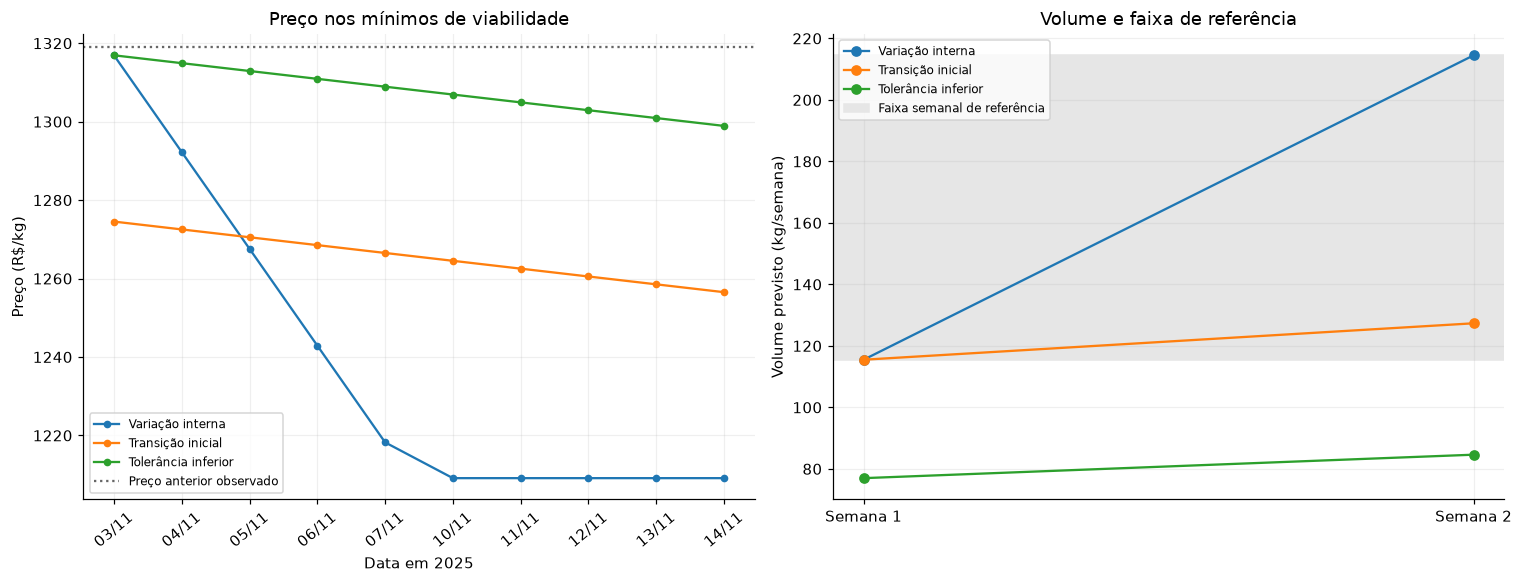

,regra,margem_prevista_rs,semana_1_volume_previsto_kg,semana_2_volume_previsto_kg,gap
0,Variação interna,43847.1239,115.5001,214.5000,0.0
1,Transição inicial,40520.3784,115.5006,127.3491,0.0
2,Tolerância inferior,33336.9354,76.9868,84.6162,0.0


**Interpretação.** Os planos atendem às condições modificadas de cada alternativa. A política de piso reduzido aceita vendas abaixo da faixa de referência; a de transição inicial ampliada admite uma mudança maior antes do primeiro dia; a de variação interna ampliada permite mudanças maiores entre decisões. As condições acompanham cada plano exportado e devem permanecer visíveis em seu uso.

In [7]:
policy_rows = []
fig, axes = plt.subplots(1, 2, figsize=(14, 5.4))
for row in thresholds:
    if row['minimum'] is None:
        continue
    result = study.evaluate(study.relaxation_at(row['rule'], row['minimum']))
    label = LABELS[row['rule']]
    daily, weekly = result['daily'], result['weekly']
    axes[0].plot(range(problem.n_days), daily['preco_kg'], 'o-', ms=4, label=label)
    axes[1].plot([1, 2], weekly['volume_previsto_kg'], 'o-', label=label)
    policy_rows.append(dict(regra=label, **summarize(result)))
policy_table = pd.DataFrame(policy_rows)
policy_table.to_csv(TABLES / 'politicas_minimas.csv', index=False)
axes[0].axhline(problem.initial_price, color='0.4', ls=':', label='Preço anterior observado')
axes[0].set_xticks(range(problem.n_days), [f'{d:%d/%m}' for d in problem.dates], rotation=40)
axes[0].set(xlabel='Data em 2025', ylabel='Preço (R$/kg)', title='Preço nos mínimos de viabilidade')
axes[1].axhspan(nominal_target*(1-problem.tol_lower), nominal_target*(1+problem.tol_upper),
               color='.9', label='Faixa semanal de referência')
axes[1].set_xticks([1, 2], ['Semana 1', 'Semana 2'])
axes[1].set(ylabel='Volume previsto (kg/semana)', title='Volume e faixa de referência')
for ax in axes:
    ax.grid(alpha=.2)
    ax.legend(fontsize=8)
fig.tight_layout()
fig.savefig(FIGURES / 'planos_minimos.png', dpi=160, bbox_inches='tight')
plt.show()
display(policy_table[['regra', 'margem_prevista_rs', 'semana_1_volume_previsto_kg',
                       'semana_2_volume_previsto_kg', 'gap']].round(4))
publicar('**Interpretação.** Os planos atendem às condições modificadas de cada alternativa. '
         'A política de piso reduzido aceita vendas abaixo da faixa de referência; a de transição '
         'inicial ampliada admite uma mudança maior antes do primeiro dia; a de variação interna '
         'ampliada permite mudanças maiores entre decisões. As condições acompanham cada plano '
         'exportado e devem permanecer visíveis em seu uso.')

## 8. Verificação, artefatos e limites de uso

**Pergunta.** Como reproduzir as análises e identificar exatamente as condições de cada plano?

**Método.** As tabelas preservam casos inviáveis e os status de término. Cada plano é recalculado
pela inferência canônica, incluindo smearing, imposto e custo. As regras ativas são verificadas
independentemente. Nas curvas de flexibilização, os limitantes do solver são usados para conferir
se os resultados são compatíveis com a ampliação do conjunto admissível.

O arquivo consolidado registra os hashes das entradas e da curva, as grades, os mínimos com seus
intervalos e todos os casos resolvidos. Os planos diários têm identificador para cruzamento com
a tabela de condições. O estudo não utiliza os dados reais do horizonte para escolher folgas.

In [8]:
cases = study.table()
assert set(cases['status']) <= {'optimal', 'infeasible'}, 'Há casos sem certificado para revisar.'
assert cases.loc[cases['margem_prevista_rs'].notna(), 'plano_verificado'].all()
for _, panel in curves.groupby('regra'):
    valid = panel.loc[panel['plano_verificado']].sort_values('valor')
    if len(valid) > 1:
        for small, large in zip(valid.iloc[:-1].itertuples(), valid.iloc[1:].itertuples()):
            assert small.margem_prevista_rs <= large.limite_superior_margem_rs + .02
plans = pd.concat([
    result['daily'].assign(case_id=result['case_id'])
    for result in study.results.values() if result['daily'] is not None
], ignore_index=True)
assert not plans['extrapolado'].any()
assert plans['custo_kg'].eq(problem.costs[0]).all()
cases.to_csv(TABLES / 'casos.csv', index=False)
plans.to_csv(PLAN_PATH, index=False)

def serializar(value):
    if isinstance(value, pd.DataFrame):
        return serializar(value.to_dict(orient='records'))
    if isinstance(value, dict):
        return {str(key): serializar(v) for key, v in value.items()}
    if isinstance(value, (list, tuple)):
        return [serializar(v) for v in value]
    if isinstance(value, (pd.Timestamp, np.datetime64)):
        return pd.Timestamp(value).isoformat()
    if isinstance(value, np.generic):
        return serializar(value.item())
    if isinstance(value, float) and not np.isfinite(value):
        return None
    return value

payload = {
    'artifact_version': 1,
    'planning_inputs_file': str(INPUT_PATH.relative_to(ROOT)),
    'planning_inputs_sha256': planning_inputs['inputs_sha256'],
    'model_file': planning_inputs['model_file'],
    'model_core_sha256': problem.artifact['model_core_sha256'],
    'model_file_sha256': model_hash,
    'decision_cutoff': planning_inputs['decision_cutoff'],
    'unit_cost_kg': float(problem.costs[0]),
    'initial_price_observed': float(problem.initial_price),
    'tax_rate': float(problem.tax_rate),
    'smearing_factor': problem.artifact['smearing_factor'],
    'holdout_used': False,
    'thresholds': thresholds,
    'curve_grids': grids,
    'combinations': combination_table.to_dict(orient='records'),
    'frontiers': frontiers.to_dict(orient='records'),
    'cases': {result['case_id']: result for result in study.results.values()},
}
RESULT_PATH.write_text(json.dumps(serializar(payload), ensure_ascii=False, indent=2, allow_nan=False)+'\n')
assert file_sha256(INPUT_PATH) == input_hash
assert file_sha256(MODEL_PATH) == model_hash
publicar(f"**Verificação concluída.** {len(cases)} casos distintos, "
         f"{int(cases['plano_verificado'].sum())} planos verificados e "
         f"{int(cases['status'].eq('infeasible').sum())} casos inviáveis provados. "
         "As entradas e a curva permaneceram idênticas durante o estudo.")

**Verificação concluída.** 214 casos distintos, 125 planos verificados e 89 casos inviáveis provados. As entradas e a curva permaneceram idênticas durante o estudo.

## 9. Entregas e interpretação operacional

| Artefato | Conteúdo |
|---|---|
| `models/otimizacao/entradas_planejamento.json` | Entradas recebidas, calendário e referências às fontes |
| `reports/tables/relaxacoes/limiares_viabilidade.csv` | Intervalos entre inviabilidade provada e planos factíveis |
| `reports/tables/relaxacoes/curvas.csv`, `curva_teto.csv` | Efeito gradual de cada regra e condição |
| `reports/tables/relaxacoes/sensibilidade_meta_nominal.csv` | Metas com tolerâncias e regras de preço fixas |
| `reports/tables/relaxacoes/combinacoes.csv`, `fronteiras.csv` | Grades e fronteiras operacionais amostradas |
| `reports/tables/relaxacoes/casos.csv`, `politicas_minimas.csv` | Condições, certificados, margens e folgas |
| `data/processed/minerva_planos_relaxacoes.csv` | Planos diários identificados pelas condições |
| `data/processed/minerva_simulacao_relaxacoes.json` | Resultado consolidado e rastreabilidade |
| `reports/figures/relaxacoes/` | Curvas, mapas e trajetórias nos mínimos |

O preço anterior, o custo, o imposto e a curva vêm dos artefatos. As faixas das análises são
escolhas computacionais explícitas. Os mínimos e as margens são resultados matemáticos condicionais
à curva e às premissas. Os limites comerciais aceitáveis para flexibilizar regras precisam ser
fornecidos pela operação; não são inferidos dos dados de venda.

O menor afrouxamento resolve a viabilidade. Uma folga adicional pode aumentar a margem prevista,
mas demanda uma mudança operacional maior. A maior margem entre alternativas com regras diferentes
não representa ganho realizado nem determina automaticamente a recomendação comercial.

**Referência do problema.** Desafio de otimização de precificação aplicado ao segmento de carnes
in natura, `docs/referencias/Minerva_Unifesp_ITA.pdf`, e restrições da instância recebida.